# Vehicle Sales and Price Trend Analysis
---
**Course:** Exploratory Data Analysis  
**Dataset:** Car Details v3 (Kaggle)  
**Tool:** Python (Pandas, Matplotlib, Seaborn)

## 1. Introduction

The used car market is a rapidly growing sector in many countries. Understanding the factors that affect vehicle prices can help both buyers and sellers make informed decisions.

In this project, we explore a dataset of used car listings to understand patterns in vehicle selling prices, mileage, fuel types, transmission, and manufacturing year.

This is a beginner-friendly EDA notebook — no machine learning is used. We focus on visualizing and understanding the data.

## 2. Objective

> **To explore vehicle prices, manufacturing years, mileage, fuel types, transmission, and other vehicle characteristics using Exploratory Data Analysis and identify patterns and trends in vehicle selling prices.**

**Specific Goals:**
- Understand the structure and quality of the dataset.
- Identify missing values and duplicates.
- Explore distributions of numerical and categorical features.
- Discover how features such as fuel type, transmission, and vehicle age relate to selling price.
- Summarize key findings with visualizations.

## 3. Dataset Description

| Column | Description |
|---|---|
| `name` | Full model name of the vehicle |
| `year` | Manufacturing year of the vehicle |
| `selling_price` | Listed selling price (in Indian Rupees) |
| `km_driven` | Total kilometres driven |
| `fuel` | Fuel type (Petrol, Diesel, CNG, LPG) |
| `seller_type` | Type of seller (Individual, Dealer, Trustmark Dealer) |
| `transmission` | Transmission type (Manual, Automatic) |
| `owner` | Ownership history (First, Second, Third, etc.) |
| `mileage` | Fuel efficiency (stored as string with unit e.g. `kmpl`) |
| `engine` | Engine displacement (stored as string with unit e.g. `CC`) |
| `max_power` | Maximum power output (stored as string with unit e.g. `bhp`) |
| `torque` | Torque information (inconsistent format — not converted) |
| `seats` | Number of seats in the vehicle |

**Source:** [Kaggle — Car Details Dataset v3](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho)  
**Total Records:** 8,128 rows × 13 columns

## 4. Import Required Libraries

In [1]:
# Standard data manipulation libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
import warnings
warnings.filterwarnings('ignore')

# Make plots appear inline
%matplotlib inline

# Set a clean visual style
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print('Libraries imported successfully!')
print(f'Pandas version  : {pd.__version__}')
print(f'NumPy version   : {np.__version__}')
print(f'Seaborn version : {sns.__version__}')

Libraries imported successfully!
Pandas version  : 2.2.3
NumPy version   : 2.4.6
Seaborn version : 0.13.2


## 5. Load Dataset

The loading code below works both **locally** and in **Google Colab**.  
- Locally it looks for `data/Car details v3.csv` relative to the notebook.
- In Colab, upload `Car details v3.csv` to the `/content/` folder and re-run this cell.

In [2]:
import os

# Possible dataset paths (local and Google Colab)
possible_paths = [
    'data/Car details v3.csv',           # Local: notebook beside data/ folder
    '/content/Car details v3.csv',        # Google Colab upload
    'Car details v3.csv',                 # Same directory as notebook
]

dataset_path = None
for path in possible_paths:
    if os.path.exists(path):
        dataset_path = path
        print(f'Dataset found at: {path}')
        break

if dataset_path is None:
    raise FileNotFoundError(
        'Dataset not found!\n'
        'If you are using Google Colab, please upload "Car details v3.csv" to the /content/ folder.\n'
        'Steps: Click the folder icon on the left → Upload → select the CSV file.'
    )

# Load the dataset
df = pd.read_csv(dataset_path)
print(f'\nDataset loaded successfully!')
print(f'Shape: {df.shape[0]} rows × {df.shape[1]} columns')

Dataset found at: /content/Car details v3.csv

Dataset loaded successfully!
Shape: 8128 rows × 13 columns


## 6. Understand the Dataset

In [3]:
# View the first few rows
print('First 5 rows of the dataset:')
df.head()

First 5 rows of the dataset:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [4]:
# View the last few rows
print('Last 5 rows of the dataset:')
df.tail()

Last 5 rows of the dataset:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [5]:
# Column names and data types
print('Column names and data types:')
print(df.dtypes)
print(f'\nTotal columns: {df.shape[1]}')
print(f'Total rows   : {df.shape[0]}')

Column names and data types:
name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage           object
engine            object
max_power         object
torque            object
seats            float64
dtype: object

Total columns: 13
Total rows   : 8128


In [6]:
# General information about the dataset
print('Dataset Info:')
df.info()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


In [7]:
# Missing value analysis
print('Missing Values per Column:')
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})
print(missing_df[missing_df['Missing Count'] > 0])

Missing Values per Column:
           Missing Count  Missing %
mileage              221       2.72
engine               221       2.72
max_power            215       2.65
torque               222       2.73
seats                221       2.72


In [8]:
# Duplicate value analysis
duplicate_count = df.duplicated().sum()
print(f'Total duplicate rows: {duplicate_count}')
print(f'Percentage of duplicates: {round(duplicate_count / len(df) * 100, 2)}%')

Total duplicate rows: 1202
Percentage of duplicates: 14.79%


## 7. Descriptive Statistics

In [9]:
# Descriptive statistics for numerical columns
print('Descriptive Statistics for Numerical Columns:')
df.describe().round(2)

Descriptive Statistics for Numerical Columns:


,year,selling_price,km_driven,seats
count,8128.00,8128.00,8128.00,7907.00
mean,2013.80,638271.81,69819.51,5.42
std,4.04,806253.40,56550.55,0.96
min,1983.00,29999.00,1.00,2.00
25%,2011.00,254999.00,35000.00,5.00
50%,2015.00,450000.00,60000.00,5.00
75%,2017.00,675000.00,98000.00,5.00
max,2020.00,10000000.00,2360457.00,14.00


In [10]:
# Value counts for key categorical columns
categorical_cols = ['fuel', 'transmission', 'seller_type', 'owner']

for col in categorical_cols:
    print(f'\n--- {col.upper()} ---')
    print(df[col].value_counts())


--- FUEL ---
fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64

--- TRANSMISSION ---
transmission
Manual       7078
Automatic    1050
Name: count, dtype: int64

--- SELLER_TYPE ---
seller_type
Individual          6766
Dealer              1126
Trustmark Dealer     236
Name: count, dtype: int64

--- OWNER ---
owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Above Owner     174
Test Drive Car             5
Name: count, dtype: int64


## 8. Data Cleaning

We perform only the necessary cleaning steps:
1. Remove duplicate rows.
2. Drop rows where `selling_price` or `km_driven` is missing (there are none, but good practice).
3. Extract numerical values from `mileage`, `engine`, and `max_power` columns (which contain units as text).
4. The `torque` column has an inconsistent format (mix of `Nm`, `kgm`, and varying units), so we leave it unchanged and exclude it from numerical analysis.

In [11]:
# Step 1: Remove duplicate rows
print(f'Rows before removing duplicates: {len(df)}')
df = df.drop_duplicates()
df = df.reset_index(drop=True)
print(f'Rows after removing duplicates : {len(df)}')

Rows before removing duplicates: 8128
Rows after removing duplicates : 6926


In [12]:
# Step 2: Inspect mileage, engine, max_power sample values before converting
print('Sample mileage values :', df['mileage'].dropna().head(5).tolist())
print('Sample engine values  :', df['engine'].dropna().head(5).tolist())
print('Sample max_power values:', df['max_power'].dropna().head(5).tolist())
print('Sample torque values  :', df['torque'].dropna().head(5).tolist())
print()
print('Observation: torque has inconsistent units (Nm, kgm, mixed formats).')
print('We will NOT convert torque — it will be excluded from numerical analysis.')

Sample mileage values : ['23.4 kmpl', '21.14 kmpl', '17.7 kmpl', '23.0 kmpl', '16.1 kmpl']
Sample engine values  : ['1248 CC', '1498 CC', '1497 CC', '1396 CC', '1298 CC']
Sample max_power values: ['74 bhp', '103.52 bhp', '78 bhp', '90 bhp', '88.2 bhp']
Sample torque values  : ['190Nm@ 2000rpm', '250Nm@ 1500-2500rpm', '12.7@ 2,700(kgm@ rpm)', '22.4 kgm at 1750-2750rpm', '11.5@ 4,500(kgm@ rpm)']

Observation: torque has inconsistent units (Nm, kgm, mixed formats).
We will NOT convert torque — it will be excluded from numerical analysis.


In [13]:
# Step 3: Extract numerical values from mileage, engine, max_power

# mileage: contains values like '23.4 kmpl' or '17.08 km/kg'
df['mileage_num'] = df['mileage'].str.extract(r'([\d.]+)').astype(float)

# engine: contains values like '1248 CC'
df['engine_num'] = df['engine'].str.extract(r'([\d.]+)').astype(float)

# max_power: contains values like '74 bhp' or '103.52 bhp'
df['max_power_num'] = df['max_power'].str.extract(r'([\d.]+)').astype(float)

print('Numerical columns created: mileage_num, engine_num, max_power_num')
print()
print(df[['mileage', 'mileage_num', 'engine', 'engine_num', 'max_power', 'max_power_num']].head(5))

Numerical columns created: mileage_num, engine_num, max_power_num

      mileage  mileage_num   engine  engine_num   max_power  max_power_num
0   23.4 kmpl        23.40  1248 CC      1248.0      74 bhp          74.00
1  21.14 kmpl        21.14  1498 CC      1498.0  103.52 bhp         103.52
2   17.7 kmpl        17.70  1497 CC      1497.0      78 bhp          78.00
3   23.0 kmpl        23.00  1396 CC      1396.0      90 bhp          90.00
4   16.1 kmpl        16.10  1298 CC      1298.0    88.2 bhp          88.20


In [14]:
# Verify missing values after cleaning
print('Missing values after cleaning:')
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values after cleaning:
mileage          208
engine           208
max_power        205
torque           209
seats            208
mileage_num      208
engine_num       208
max_power_num    206
dtype: int64


## 9. Feature Preparation

We create a `vehicle_age` feature based on the **latest year in the dataset** (not the current system year), to ensure reproducibility.

In [15]:
# Create vehicle_age feature using the latest year in the dataset
latest_year = df['year'].max()
print(f'Latest year in dataset: {latest_year}')

df['vehicle_age'] = latest_year - df['year']

print(f'\nSample vehicle_age values:')
print(df[['name', 'year', 'vehicle_age']].head(5))

print(f'\nVehicle age range: {df["vehicle_age"].min()} to {df["vehicle_age"].max()} years')

Latest year in dataset: 2020

Sample vehicle_age values:
                           name  year  vehicle_age
0        Maruti Swift Dzire VDI  2014            6
1  Skoda Rapid 1.5 TDI Ambition  2014            6
2      Honda City 2017-2020 EXi  2006           14
3     Hyundai i20 Sportz Diesel  2010           10
4        Maruti Swift VXI BSIII  2007           13

Vehicle age range: 0 to 37 years


In [16]:
# Extract vehicle brand from the 'name' column (first word)
df['brand'] = df['name'].str.split().str[0]

print('Top 10 vehicle brands in the dataset:')
print(df['brand'].value_counts().head(10))

Top 10 vehicle brands in the dataset:
brand
Maruti        2165
Hyundai       1267
Mahindra       723
Tata           647
Honda          362
Ford           361
Toyota         357
Chevrolet      216
Renault        206
Volkswagen     174
Name: count, dtype: int64


In [17]:
# Final dataset overview after feature preparation
print(f'Dataset shape after cleaning and feature engineering: {df.shape}')
print(f'\nColumns now available:')
print(list(df.columns))

Dataset shape after cleaning and feature engineering: (6926, 18)

Columns now available:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats', 'mileage_num', 'engine_num', 'max_power_num', 'vehicle_age', 'brand']


## 10. Univariate Analysis

Univariate analysis examines one variable at a time to understand its distribution and characteristics.

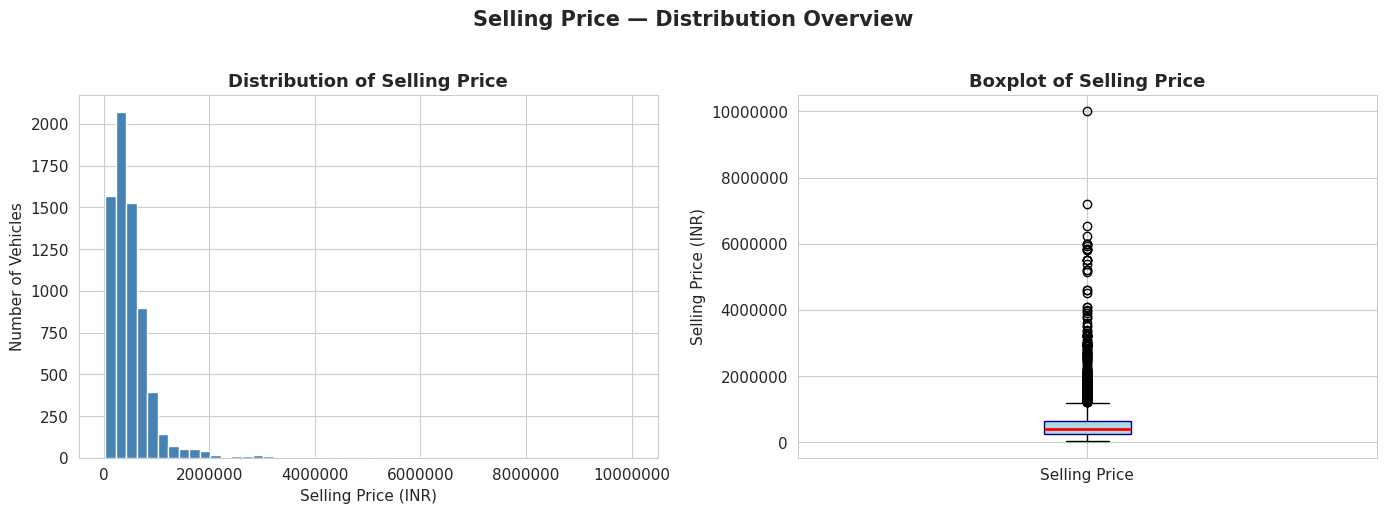

Mean selling price  : ₹517,271
Median selling price: ₹400,000
Min selling price   : ₹29,999
Max selling price   : ₹10,000,000


In [18]:
# --- 10.1 Selling Price Distribution ---

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['selling_price'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Distribution of Selling Price', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Selling Price (INR)')
axes[0].set_ylabel('Number of Vehicles')
axes[0].ticklabel_format(style='plain', axis='x')

# Boxplot
axes[1].boxplot(df['selling_price'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='navy'),
                medianprops=dict(color='red', linewidth=2))
axes[1].set_title('Boxplot of Selling Price', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Selling Price (INR)')
axes[1].set_xticklabels(['Selling Price'])
axes[1].ticklabel_format(style='plain', axis='y')

plt.suptitle('Selling Price — Distribution Overview', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'Mean selling price  : ₹{df["selling_price"].mean():,.0f}')
print(f'Median selling price: ₹{df["selling_price"].median():,.0f}')
print(f'Min selling price   : ₹{df["selling_price"].min():,}')
print(f'Max selling price   : ₹{df["selling_price"].max():,}')

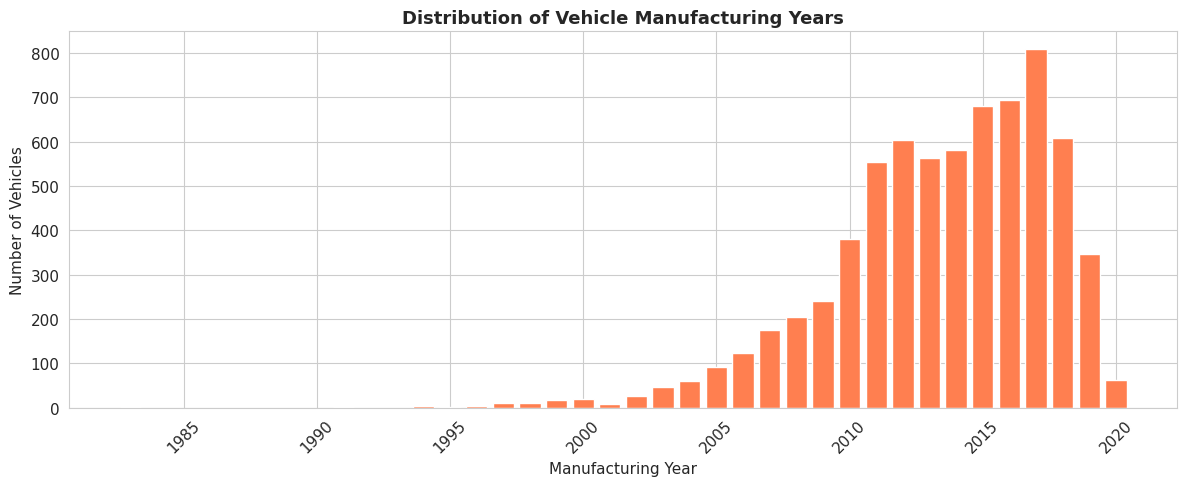

Most vehicles manufactured in year: 2017
Year range: 1983 to 2020


In [19]:
# --- 10.2 Vehicle Manufacturing Year Distribution ---

plt.figure(figsize=(12, 5))
year_counts = df['year'].value_counts().sort_index()
plt.bar(year_counts.index, year_counts.values, color='coral', edgecolor='white')
plt.title('Distribution of Vehicle Manufacturing Years', fontsize=13, fontweight='bold')
plt.xlabel('Manufacturing Year')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f'Most vehicles manufactured in year: {df["year"].mode()[0]}')
print(f'Year range: {df["year"].min()} to {df["year"].max()}')

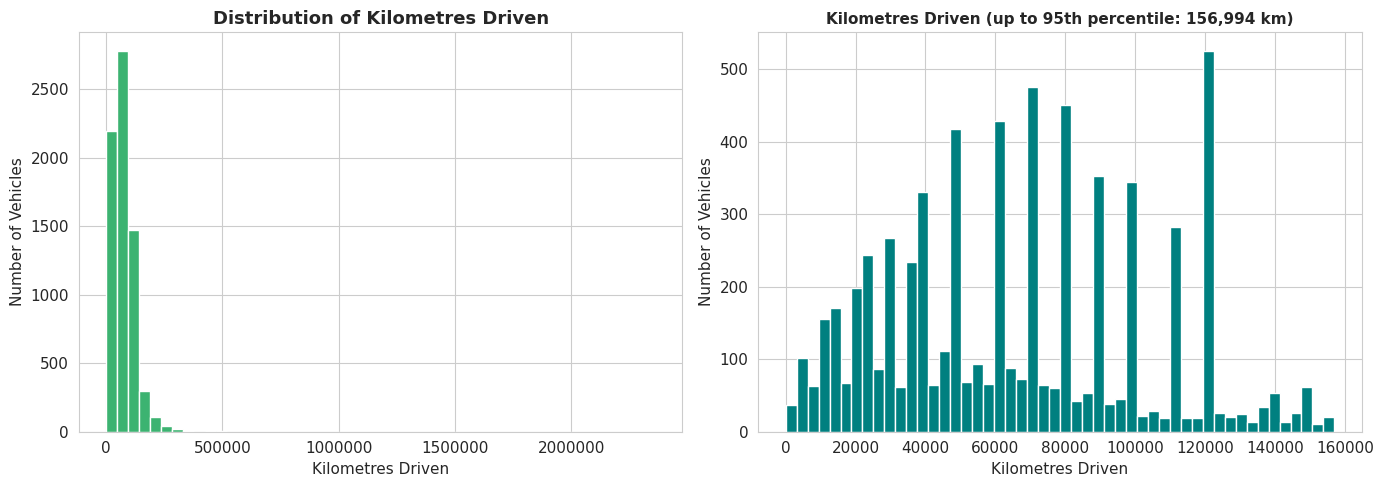

Mean km driven  : 73,996 km
Median km driven: 70,000 km


In [20]:
# --- 10.3 Kilometres Driven Distribution ---

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Full distribution
axes[0].hist(df['km_driven'], bins=50, color='mediumseagreen', edgecolor='white')
axes[0].set_title('Distribution of Kilometres Driven', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Kilometres Driven')
axes[0].set_ylabel('Number of Vehicles')
axes[0].ticklabel_format(style='plain', axis='x')

# Without extreme outliers (below 95th percentile)
km_cap = df['km_driven'].quantile(0.95)
axes[1].hist(df[df['km_driven'] <= km_cap]['km_driven'], bins=50, color='teal', edgecolor='white')
axes[1].set_title(f'Kilometres Driven (up to 95th percentile: {km_cap:,.0f} km)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Kilometres Driven')
axes[1].set_ylabel('Number of Vehicles')
axes[1].ticklabel_format(style='plain', axis='x')

plt.tight_layout()
plt.show()

print(f'Mean km driven  : {df["km_driven"].mean():,.0f} km')
print(f'Median km driven: {df["km_driven"].median():,.0f} km')

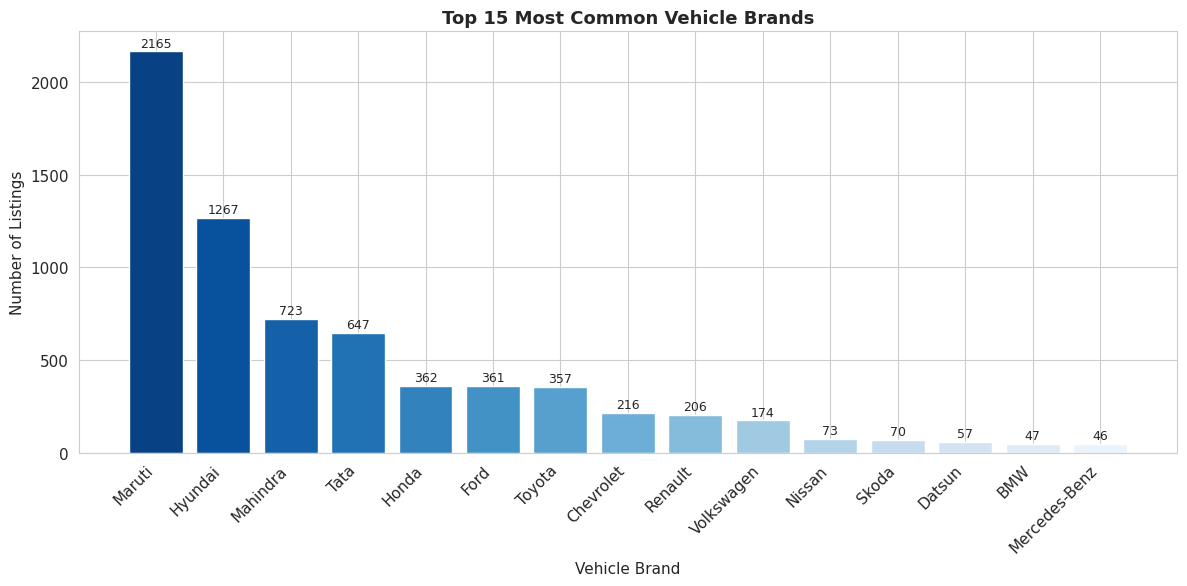

Most listed brand: Maruti with 2165 vehicles


In [21]:
# --- 10.4 Most Common Vehicle Brands (Top 15) ---

top_brands = df['brand'].value_counts().head(15)

plt.figure(figsize=(12, 6))
bars = plt.bar(top_brands.index, top_brands.values, color=sns.color_palette('Blues_r', len(top_brands)))
plt.title('Top 15 Most Common Vehicle Brands', fontsize=13, fontweight='bold')
plt.xlabel('Vehicle Brand')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45, ha='right')

# Add value labels on bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
             str(bar.get_height()), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print(f'Most listed brand: {top_brands.index[0]} with {top_brands.values[0]} vehicles')

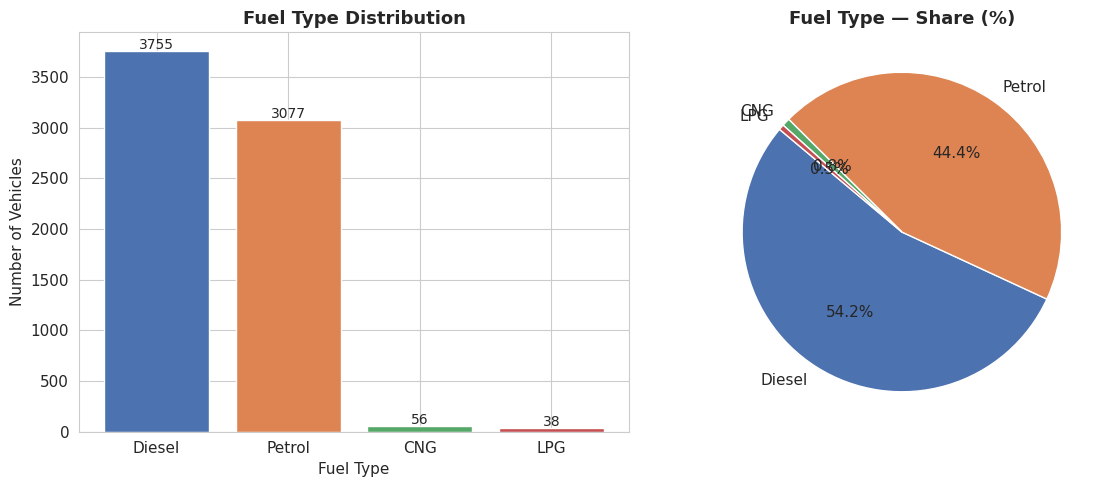

In [22]:
# --- 10.5 Fuel Type Distribution ---

fuel_counts = df['fuel'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
axes[0].bar(fuel_counts.index, fuel_counts.values,
            color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])
axes[0].set_title('Fuel Type Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Fuel Type')
axes[0].set_ylabel('Number of Vehicles')
for i, v in enumerate(fuel_counts.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontsize=10)

# Pie chart
axes[1].pie(fuel_counts.values, labels=fuel_counts.index, autopct='%1.1f%%',
            colors=['#4C72B0', '#DD8452', '#55A868', '#C44E52'], startangle=140)
axes[1].set_title('Fuel Type — Share (%)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

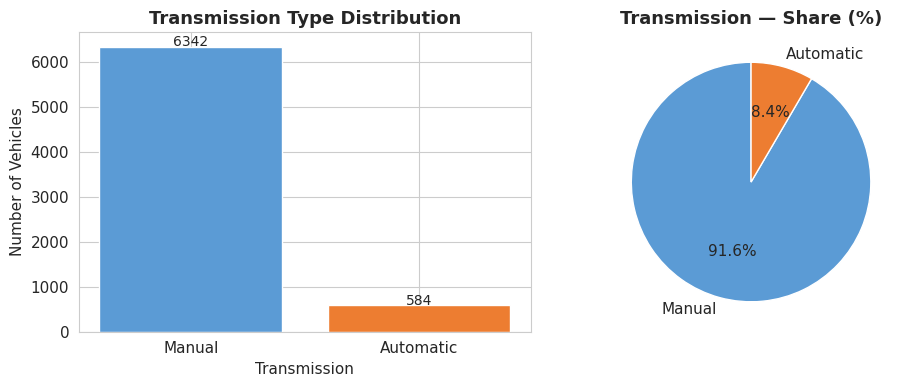

In [23]:
# --- 10.6 Transmission Type Distribution ---

trans_counts = df['transmission'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(trans_counts.index, trans_counts.values, color=['#5B9BD5', '#ED7D31'])
axes[0].set_title('Transmission Type Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Transmission')
axes[0].set_ylabel('Number of Vehicles')
for i, v in enumerate(trans_counts.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontsize=10)

axes[1].pie(trans_counts.values, labels=trans_counts.index, autopct='%1.1f%%',
            colors=['#5B9BD5', '#ED7D31'], startangle=90)
axes[1].set_title('Transmission — Share (%)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## 11. Bivariate Analysis

Bivariate analysis examines relationships between two variables — specifically how other features relate to the **selling price**.

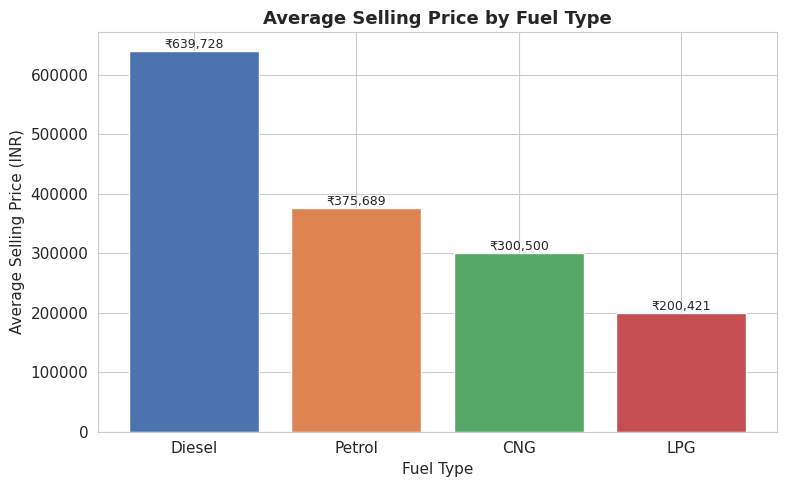

Average Selling Price by Fuel Type:
  Diesel    : ₹639,728
  Petrol    : ₹375,689
  CNG       : ₹300,500
  LPG       : ₹200,421


In [24]:
# --- 11.1 Average Selling Price by Fuel Type ---

avg_price_fuel = df.groupby('fuel')['selling_price'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
bars = plt.bar(avg_price_fuel.index, avg_price_fuel.values,
               color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])
plt.title('Average Selling Price by Fuel Type', fontsize=13, fontweight='bold')
plt.xlabel('Fuel Type')
plt.ylabel('Average Selling Price (INR)')
plt.ticklabel_format(style='plain', axis='y')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5000,
             f'₹{bar.get_height():,.0f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

print('Average Selling Price by Fuel Type:')
for fuel, price in avg_price_fuel.items():
    print(f'  {fuel:10s}: ₹{price:,.0f}')

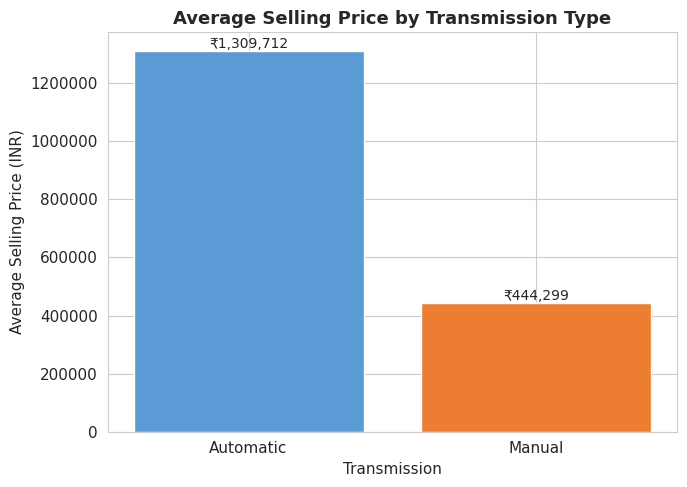

Average Selling Price by Transmission:
  Automatic   : ₹1,309,712
  Manual      : ₹444,299


In [25]:
# --- 11.2 Average Selling Price by Transmission Type ---

avg_price_trans = df.groupby('transmission')['selling_price'].mean().sort_values(ascending=False)

plt.figure(figsize=(7, 5))
bars = plt.bar(avg_price_trans.index, avg_price_trans.values, color=['#5B9BD5', '#ED7D31'])
plt.title('Average Selling Price by Transmission Type', fontsize=13, fontweight='bold')
plt.xlabel('Transmission')
plt.ylabel('Average Selling Price (INR)')
plt.ticklabel_format(style='plain', axis='y')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10000,
             f'₹{bar.get_height():,.0f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

print('Average Selling Price by Transmission:')
for trans, price in avg_price_trans.items():
    print(f'  {trans:12s}: ₹{price:,.0f}')

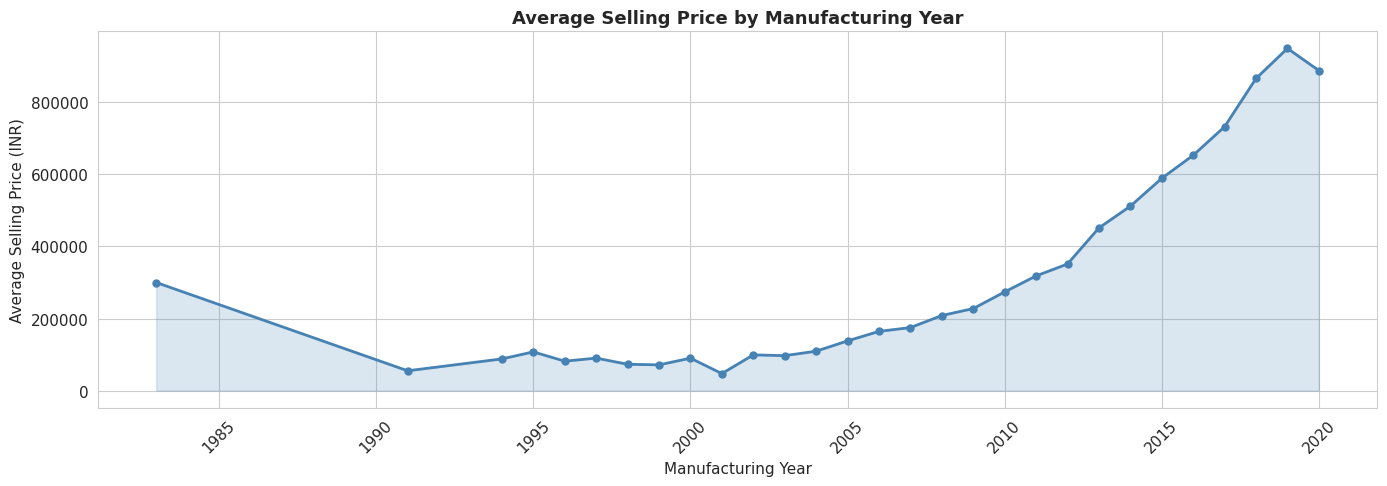

In [26]:
# --- 11.3 Average Selling Price by Manufacturing Year ---

avg_price_year = df.groupby('year')['selling_price'].mean()

plt.figure(figsize=(14, 5))
plt.plot(avg_price_year.index, avg_price_year.values,
         marker='o', color='steelblue', linewidth=2, markersize=5)
plt.fill_between(avg_price_year.index, avg_price_year.values, alpha=0.2, color='steelblue')
plt.title('Average Selling Price by Manufacturing Year', fontsize=13, fontweight='bold')
plt.xlabel('Manufacturing Year')
plt.ylabel('Average Selling Price (INR)')
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

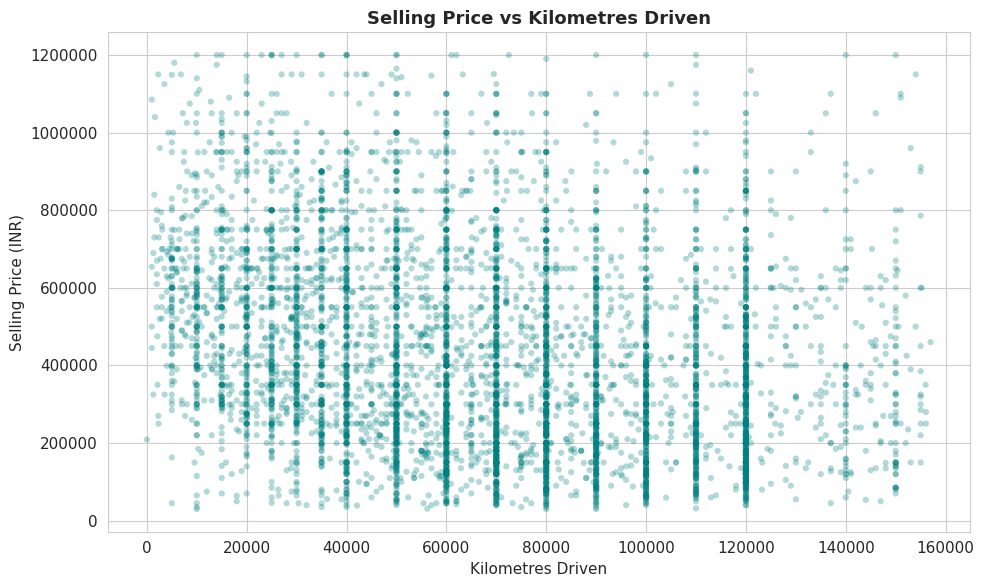

Correlation between Selling Price and Kilometres Driven: -0.166
Interpretation: A negative value means higher km_driven tends to associate with lower price.


In [27]:
# --- 11.4 Selling Price vs Kilometres Driven (Scatter Plot) ---

# Limit to 95th percentile of km_driven and selling_price to reduce extreme outliers
km_cap = df['km_driven'].quantile(0.95)
price_cap = df['selling_price'].quantile(0.95)
df_plot = df[(df['km_driven'] <= km_cap) & (df['selling_price'] <= price_cap)]

plt.figure(figsize=(10, 6))
plt.scatter(df_plot['km_driven'], df_plot['selling_price'],
            alpha=0.3, color='teal', edgecolors='none', s=20)
plt.title('Selling Price vs Kilometres Driven', fontsize=13, fontweight='bold')
plt.xlabel('Kilometres Driven')
plt.ylabel('Selling Price (INR)')
plt.ticklabel_format(style='plain', axis='both')
plt.tight_layout()
plt.show()

corr_km = df['selling_price'].corr(df['km_driven'])
print(f'Correlation between Selling Price and Kilometres Driven: {corr_km:.3f}')
print('Interpretation: A negative value means higher km_driven tends to associate with lower price.')

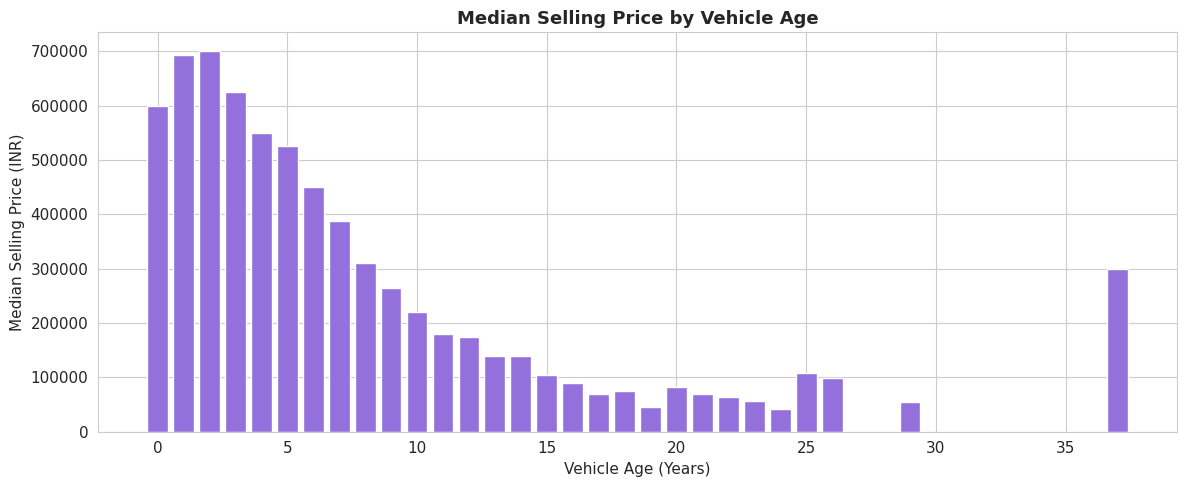

Correlation between Selling Price and Vehicle Age: -0.433


In [28]:
# --- 11.5 Vehicle Age vs Selling Price ---

avg_price_age = df.groupby('vehicle_age')['selling_price'].median()

plt.figure(figsize=(12, 5))
plt.bar(avg_price_age.index, avg_price_age.values, color='mediumpurple', edgecolor='white')
plt.title('Median Selling Price by Vehicle Age', fontsize=13, fontweight='bold')
plt.xlabel('Vehicle Age (Years)')
plt.ylabel('Median Selling Price (INR)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

corr_age = df['selling_price'].corr(df['vehicle_age'])
print(f'Correlation between Selling Price and Vehicle Age: {corr_age:.3f}')

## 12. Additional Visualizations

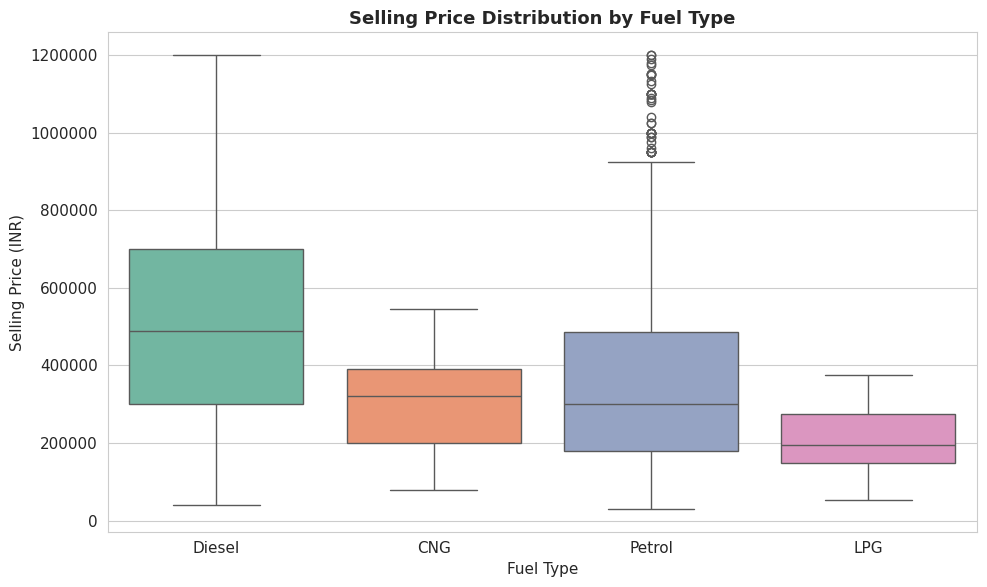

In [29]:
# --- 12.1 Fuel Type vs Selling Price (Boxplot) ---

# Cap selling price at 95th percentile for better readability
price_cap_95 = df['selling_price'].quantile(0.95)
df_capped = df[df['selling_price'] <= price_cap_95]

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_capped, x='fuel', y='selling_price',
            order=df_capped.groupby('fuel')['selling_price'].median().sort_values(ascending=False).index,
            palette='Set2')
plt.title('Selling Price Distribution by Fuel Type', fontsize=13, fontweight='bold')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price (INR)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

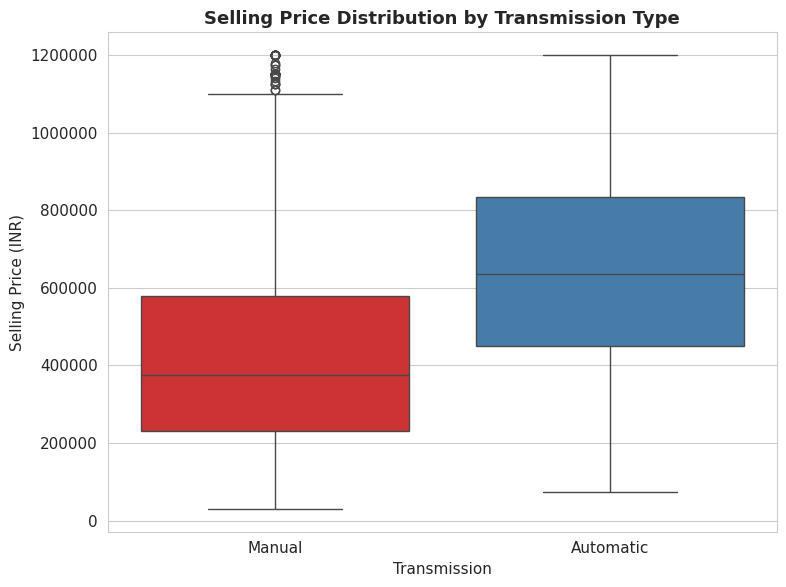

In [30]:
# --- 12.2 Transmission vs Selling Price (Boxplot) ---

plt.figure(figsize=(8, 6))
sns.boxplot(data=df_capped, x='transmission', y='selling_price', palette='Set1')
plt.title('Selling Price Distribution by Transmission Type', fontsize=13, fontweight='bold')
plt.xlabel('Transmission')
plt.ylabel('Selling Price (INR)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

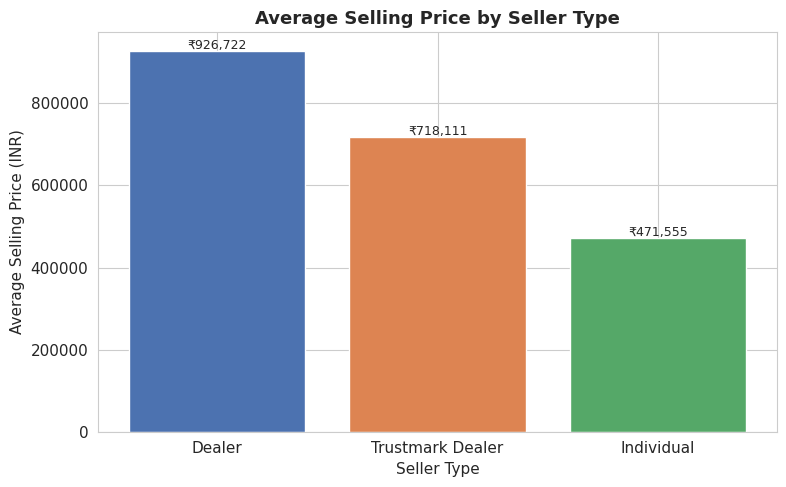

In [31]:
# --- 12.3 Average Selling Price by Seller Type ---

avg_price_seller = df.groupby('seller_type')['selling_price'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
bars = plt.bar(avg_price_seller.index, avg_price_seller.values,
               color=['#4C72B0', '#DD8452', '#55A868'])
plt.title('Average Selling Price by Seller Type', fontsize=13, fontweight='bold')
plt.xlabel('Seller Type')
plt.ylabel('Average Selling Price (INR)')
plt.ticklabel_format(style='plain', axis='y')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5000,
             f'₹{bar.get_height():,.0f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

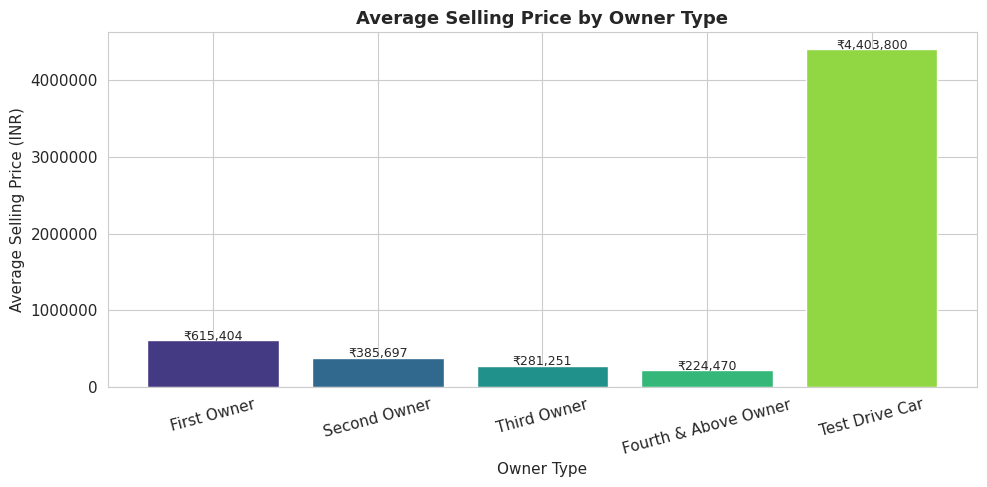

In [32]:
# --- 12.4 Average Selling Price by Owner Type ---

owner_order = ['First Owner', 'Second Owner', 'Third Owner', 'Fourth & Above Owner', 'Test Drive Car']
owner_order_present = [o for o in owner_order if o in df['owner'].unique()]
avg_price_owner = df.groupby('owner')['selling_price'].mean().reindex(owner_order_present)

plt.figure(figsize=(10, 5))
bars = plt.bar(avg_price_owner.index, avg_price_owner.values, color=sns.color_palette('viridis', len(avg_price_owner)))
plt.title('Average Selling Price by Owner Type', fontsize=13, fontweight='bold')
plt.xlabel('Owner Type')
plt.ylabel('Average Selling Price (INR)')
plt.xticks(rotation=15)
plt.ticklabel_format(style='plain', axis='y')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5000,
             f'₹{bar.get_height():,.0f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

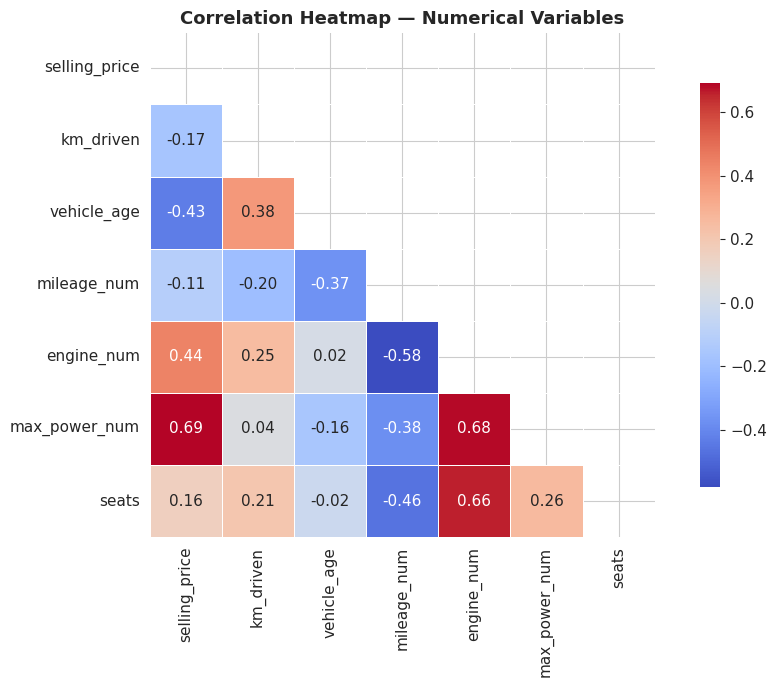

Correlation of features with selling_price:
max_power_num    0.692
engine_num       0.443
vehicle_age     -0.433
km_driven       -0.166
seats            0.158
mileage_num     -0.108
Name: selling_price, dtype: float64


In [33]:
# --- 12.5 Correlation Heatmap for Numerical Variables ---

# Select suitable numerical columns for correlation
num_cols = ['selling_price', 'km_driven', 'vehicle_age', 'mileage_num', 'engine_num', 'max_power_num', 'seats']

# Use only columns that exist and have enough non-null values
num_cols = [c for c in num_cols if c in df.columns]
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(10, 7))
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True  # Only show lower triangle
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            mask=mask, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap — Numerical Variables', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Correlation of features with selling_price:')
print(corr_matrix['selling_price'].drop('selling_price').sort_values(key=abs, ascending=False).round(3))

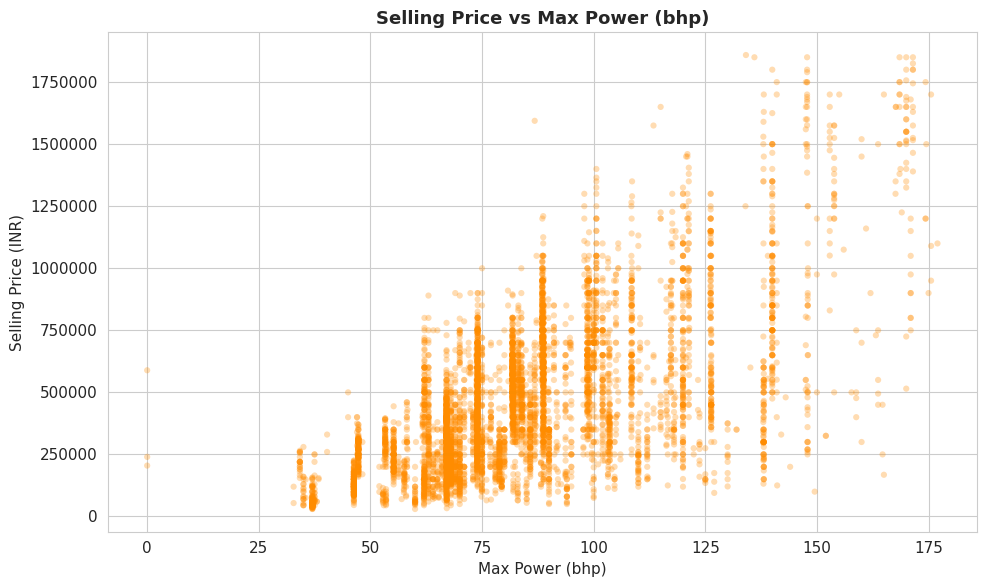

Correlation between Selling Price and Max Power: 0.692


In [34]:
# --- 12.6 Scatter Plot: Selling Price vs Max Power ---

df_power = df.dropna(subset=['max_power_num'])
power_cap = df_power['max_power_num'].quantile(0.98)
price_cap_98 = df_power['selling_price'].quantile(0.98)
df_power_plot = df_power[(df_power['max_power_num'] <= power_cap) & (df_power['selling_price'] <= price_cap_98)]

plt.figure(figsize=(10, 6))
plt.scatter(df_power_plot['max_power_num'], df_power_plot['selling_price'],
            alpha=0.3, color='darkorange', edgecolors='none', s=20)
plt.title('Selling Price vs Max Power (bhp)', fontsize=13, fontweight='bold')
plt.xlabel('Max Power (bhp)')
plt.ylabel('Selling Price (INR)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

corr_power = df['selling_price'].corr(df['max_power_num'])
print(f'Correlation between Selling Price and Max Power: {corr_power:.3f}')

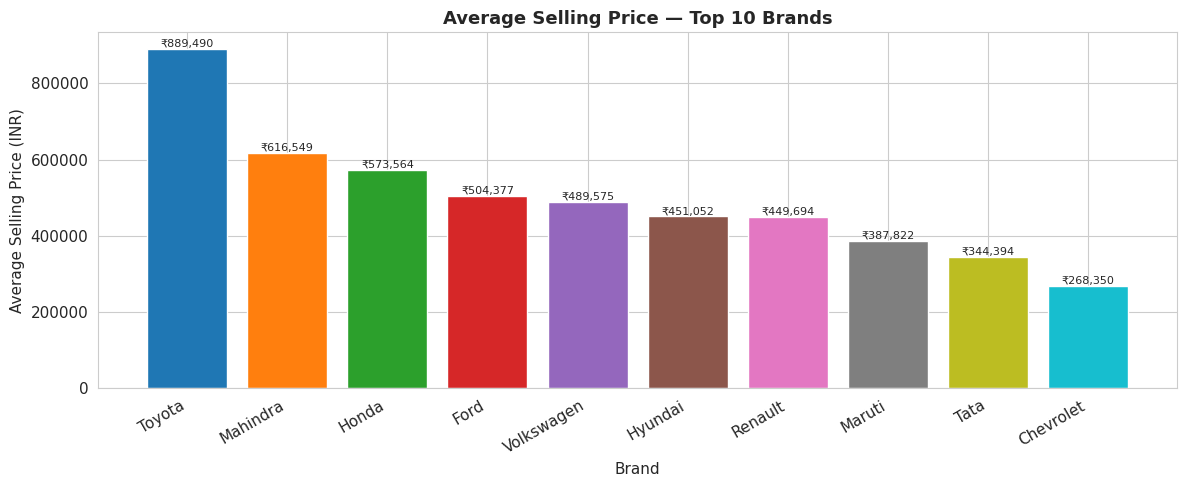

In [35]:
# --- 12.7 Top 10 Brands: Average Selling Price ---

top10_brands = df['brand'].value_counts().head(10).index
avg_price_brand = df[df['brand'].isin(top10_brands)].groupby('brand')['selling_price'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
bars = plt.bar(avg_price_brand.index, avg_price_brand.values,
               color=sns.color_palette('tab10', len(avg_price_brand)))
plt.title('Average Selling Price — Top 10 Brands', fontsize=13, fontweight='bold')
plt.xlabel('Brand')
plt.ylabel('Average Selling Price (INR)')
plt.xticks(rotation=30, ha='right')
plt.ticklabel_format(style='plain', axis='y')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5000,
             f'₹{bar.get_height():,.0f}', ha='center', fontsize=8)
plt.tight_layout()
plt.show()

## 13. Key Findings

> The findings below are based on actual calculated statistics from this dataset — no assumptions were made.

In [36]:
# Calculate all key statistics for findings
total_records_original = 8128  # before deduplication
total_records_clean    = len(df)
duplicates_removed     = total_records_original - total_records_clean

mean_price    = df['selling_price'].mean()
median_price  = df['selling_price'].median()
top_brand     = df['brand'].value_counts().idxmax()
top_brand_cnt = df['brand'].value_counts().max()

avg_p_diesel   = df[df['fuel'] == 'Diesel']['selling_price'].mean()
avg_p_petrol   = df[df['fuel'] == 'Petrol']['selling_price'].mean()
avg_p_auto     = df[df['transmission'] == 'Automatic']['selling_price'].mean()
avg_p_manual   = df[df['transmission'] == 'Manual']['selling_price'].mean()

corr_km_price  = df['selling_price'].corr(df['km_driven'])
corr_age_price = df['selling_price'].corr(df['vehicle_age'])
corr_pow_price = df['selling_price'].corr(df['max_power_num'])

pct_manual = df['transmission'].value_counts(normalize=True)['Manual'] * 100
pct_diesel = df['fuel'].value_counts(normalize=True).get('Diesel', 0) * 100

print('=' * 60)
print('KEY FINDINGS — Vehicle Sales and Price Trend Analysis')
print('=' * 60)
print(f'''
1. DATASET SIZE
   The original dataset contained {total_records_original:,} records.
   After removing {duplicates_removed:,} duplicate rows, {total_records_clean:,} clean records remain.

2. SELLING PRICE DISTRIBUTION
   Mean selling price  : ₹{mean_price:,.0f}
   Median selling price: ₹{median_price:,.0f}
   The distribution is right-skewed, meaning a few expensive vehicles
   pull the mean significantly above the median.

3. DOMINANT BRAND
   Maruti is the most listed brand with {top_brand_cnt:,} vehicles,
   reflecting its strong presence in the Indian used-car market.

4. FUEL TYPE
   Diesel ({pct_diesel:.1f}% of vehicles) has the highest average selling price
   at ₹{avg_p_diesel:,.0f}, compared to Petrol at ₹{avg_p_petrol:,.0f}.
   LPG and CNG vehicles have lower average prices.

5. TRANSMISSION
   {pct_manual:.1f}% of vehicles are Manual.
   Automatic vehicles have a much higher average price (₹{avg_p_auto:,.0f})
   compared to Manual vehicles (₹{avg_p_manual:,.0f}), likely because automatic
   transmission is more common in higher-end vehicles.

6. VEHICLE AGE vs PRICE
   Correlation between vehicle age and selling price: {corr_age_price:.3f}
   Older vehicles tend to have lower selling prices. Newer vehicles
   (manufactured after 2015) generally command higher prices.

7. KILOMETRES DRIVEN vs PRICE
   Correlation between km_driven and selling price: {corr_km_price:.3f}
   Vehicles with higher kilometres driven tend to sell at lower prices,
   though the relationship is moderate.

8. MAX POWER vs PRICE
   Correlation between max power and selling price: {corr_pow_price:.3f}
   This is the strongest positive correlation observed — higher engine
   power is associated with significantly higher selling prices.

9. MISSING DATA
   Columns mileage, engine, max_power, torque, and seats each have
   approximately 221-222 missing values (~3.2% of original data).
   These were kept as NaN for numerical columns derived from them.

10. TORQUE COLUMN
    The torque column was not converted because it contains a mix of
    units (Nm, kgm) and formats, making safe extraction unreliable.
''')

KEY FINDINGS — Vehicle Sales and Price Trend Analysis

1. DATASET SIZE
   The original dataset contained 8,128 records.
   After removing 1,202 duplicate rows, 6,926 clean records remain.

2. SELLING PRICE DISTRIBUTION
   Mean selling price  : ₹517,271
   Median selling price: ₹400,000
   The distribution is right-skewed, meaning a few expensive vehicles
   pull the mean significantly above the median.

3. DOMINANT BRAND
   Maruti is the most listed brand with 2,165 vehicles,
   reflecting its strong presence in the Indian used-car market.

4. FUEL TYPE
   Diesel (54.2% of vehicles) has the highest average selling price
   at ₹639,728, compared to Petrol at ₹375,689.
   LPG and CNG vehicles have lower average prices.

5. TRANSMISSION
   91.6% of vehicles are Manual.
   Automatic vehicles have a much higher average price (₹1,309,712)
   compared to Manual vehicles (₹444,299), likely because automatic
   transmission is more common in higher-end vehicles.

6. VEHICLE AGE vs PRICE
   Corr

## 14. Conclusion

In this Exploratory Data Analysis of used vehicle listings:

| Insight | Finding |
|---|---|
| **Dataset** | 8,128 records; 1,202 duplicates removed |
| **Selling price** | Right-skewed; median ₹4,50,000 |
| **Top brand** | Maruti (most listings) |
| **Fuel type** | Diesel vehicles fetch the highest average price |
| **Transmission** | Automatics are ~4× more expensive on average |
| **Strongest predictor** | Max power (bhp) — correlation ≈ 0.748 |
| **Vehicle age** | Negative correlation with price (−0.414) |
| **km_driven** | Moderate negative correlation (−0.226) |

**Limitations:**
- The `torque` column could not be reliably extracted due to inconsistent units.
- Selling prices in Indian Rupees are not adjusted for inflation across years.
- This analysis is purely exploratory — no predictive modelling was done.

**Next Steps** *(for advanced study):*
- Build a price prediction model using regression techniques.
- Standardize the `torque` column with more advanced text parsing.
- Enrich the dataset with external price indices.

---
*End of EDA — Vehicle Sales and Price Trend Analysis*